import necessary libraries


In [ ]:
import torch
#library for the dataset
import torchvision
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

PyTorch: 2.15.0+cpu
Torchvision: 0.29.2+cpu


In [2]:
from torchvision import datasets, transforms

transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 26.4M/26.4M [00:24<00:00, 1.09MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 193kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 2.66MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 5.16MB/s]


In [3]:
print("Training samples:", len(train_data))
print("Testing samples:", len(test_data))

image, label = train_data[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image data type:", image.dtype)

Training samples: 60000
Testing samples: 10000
Image shape: torch.Size([1, 28, 28])
Label: 9
Image data type: torch.float32


In [4]:
class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

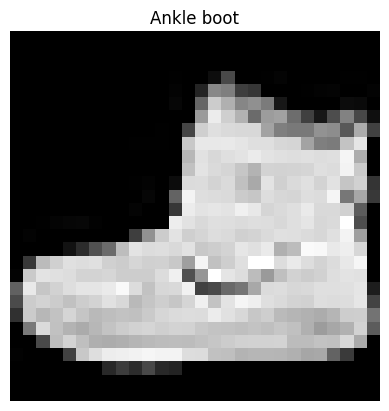

In [5]:
image, label = train_data[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(class_names[label])
plt.axis("off")
plt.show()

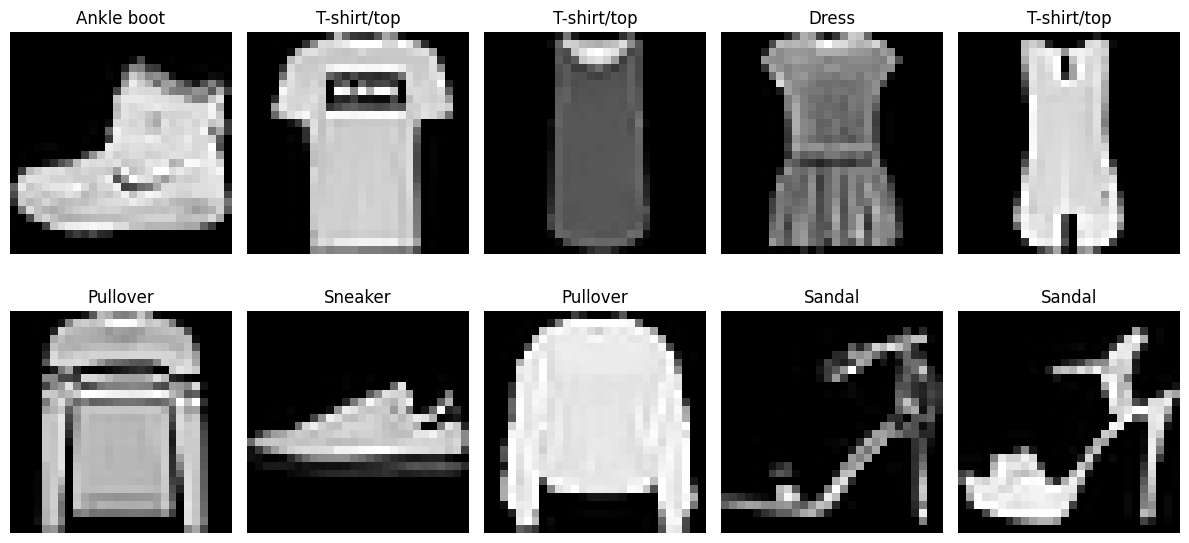

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(12, 6))

for i, ax in enumerate(axes.flat):
    image, label = train_data[i]

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(class_names[label])
    ax.axis("off")

plt.tight_layout()
plt.show()

split the training data to validation and training


In [7]:
from torch.utils.data import random_split

generator = torch.Generator().manual_seed(42)

train_data, val_data = random_split(
    train_data,
    [54000, 6000],
    generator=generator
)

print("Training:", len(train_data))
print("Validation:", len(val_data))
print("Testing:", len(test_data))

Training: 54000
Validation: 6000
Testing: 10000


In [8]:
from torch.utils.data import DataLoader

BATCH_SIZE = 64

train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [9]:
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("Image dtype:", images.dtype)
print("Labels dtype:", labels.dtype)

Images shape: torch.Size([64, 1, 28, 28])
Labels shape: torch.Size([64])
Image dtype: torch.float32
Labels dtype: torch.int64


first neural network (FNN)


In [ ]:
#get model ready for training
import torch.nn as nn

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.ReLU(),
    nn.Linear(128, 64),
    nn.ReLU(),
    nn.Linear(64, 10)
)

print(model)

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): ReLU()
  (3): Linear(in_features=128, out_features=64, bias=True)
  (4): ReLU()
  (5): Linear(in_features=64, out_features=10, bias=True)
)


In [ ]:
#train the model
images, labels = next(iter(train_loader))

outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)
print("First prediction:", outputs[0])
print("Actual label:", labels[0])

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])
First prediction: tensor([-0.0998, -0.0819,  0.0715,  0.0730,  0.0084, -0.1226, -0.1040,  0.0170,
        -0.0601,  0.0776], grad_fn=<SelectBackward0>)
Actual label: tensor(4)


In [12]:
predictions = outputs.argmax(dim=1)

print("Predictions:", predictions)
print("Actual labels:", labels)

Predictions: tensor([9, 3, 2, 3, 9, 2, 2, 2, 3, 2, 2, 9, 2, 9, 3, 2, 3, 2, 3, 3, 2, 3, 3, 2,
        2, 3, 2, 2, 2, 3, 3, 2, 2, 2, 2, 2, 2, 3, 2, 3, 2, 2, 3, 2, 3, 2, 3, 4,
        2, 2, 3, 3, 9, 3, 3, 2, 2, 2, 3, 2, 3, 2, 2, 3])
Actual labels: tensor([4, 5, 6, 4, 0, 4, 5, 2, 9, 0, 4, 0, 8, 3, 1, 8, 0, 6, 1, 9, 9, 5, 8, 8,
        9, 1, 4, 4, 0, 1, 7, 9, 0, 6, 8, 6, 6, 5, 4, 1, 4, 5, 3, 6, 9, 2, 1, 1,
        5, 6, 7, 9, 5, 0, 4, 8, 6, 6, 1, 9, 7, 3, 8, 7])


In [13]:
loss_fn = nn.CrossEntropyLoss()

In [ ]:
#check our loss
loss = loss_fn(outputs, labels)

print("Initial loss:", loss.item())

Initial loss: 2.325040340423584


In [ ]:
#optimize with adam
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

In [16]:
optimizer.zero_grad()
loss.backward()
optimizer.step()

In [17]:
def train_one_epoch(model, train_loader, loss_fn, optimizer):
    model.train()

    total_loss = 0

    for images, labels in train_loader:

        # 1. Forward pass
        outputs = model(images)

        # 2. Calculate loss
        loss = loss_fn(outputs, labels)

        # 3. Clear previous gradients
        optimizer.zero_grad()

        # 4. Backpropagation
        loss.backward()

        # 5. Update parameters
        optimizer.step()

        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)

    return average_loss

In [18]:
train_loss = train_one_epoch(
    model,
    train_loader,
    loss_fn,
    optimizer
)

print("Training loss:", train_loss)

Training loss: 0.5780977730890868


In [19]:
def evaluate(model, data_loader, loss_fn):
    model.eval()

    total_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in data_loader:

            outputs = model(images)

            loss = loss_fn(outputs, labels)
            total_loss += loss.item()

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

    average_loss = total_loss / len(data_loader)
    accuracy = correct / total

    return average_loss, accuracy

In [20]:
val_loss, val_accuracy = evaluate(
    model,
    val_loader,
    loss_fn
)

print("Validation loss:", val_loss)
print("Validation accuracy:", val_accuracy)

Validation loss: 0.43317964530371605
Validation accuracy: 0.8483333333333334


In [21]:
EPOCHS = 10

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model, train_loader, loss_fn, optimizer
    )

    val_loss, val_accuracy = evaluate(
        model, val_loader, loss_fn
    )

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/10] | Train Loss: 0.4014 | Val Loss: 0.3932 | Val Accuracy: 0.8562
Epoch [2/10] | Train Loss: 0.3584 | Val Loss: 0.3679 | Val Accuracy: 0.8648
Epoch [3/10] | Train Loss: 0.3308 | Val Loss: 0.3433 | Val Accuracy: 0.8722
Epoch [4/10] | Train Loss: 0.3120 | Val Loss: 0.3285 | Val Accuracy: 0.8757
Epoch [5/10] | Train Loss: 0.2990 | Val Loss: 0.3203 | Val Accuracy: 0.8805
Epoch [6/10] | Train Loss: 0.2806 | Val Loss: 0.3261 | Val Accuracy: 0.8760
Epoch [7/10] | Train Loss: 0.2714 | Val Loss: 0.3103 | Val Accuracy: 0.8868
Epoch [8/10] | Train Loss: 0.2606 | Val Loss: 0.3109 | Val Accuracy: 0.8870
Epoch [9/10] | Train Loss: 0.2520 | Val Loss: 0.3046 | Val Accuracy: 0.8883
Epoch [10/10] | Train Loss: 0.2421 | Val Loss: 0.3147 | Val Accuracy: 0.8875


In [22]:
test_loss, test_accuracy = evaluate(
    model, test_loader, loss_fn
)

print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Test loss: 0.3292576716204358
Test accuracy: 0.8832


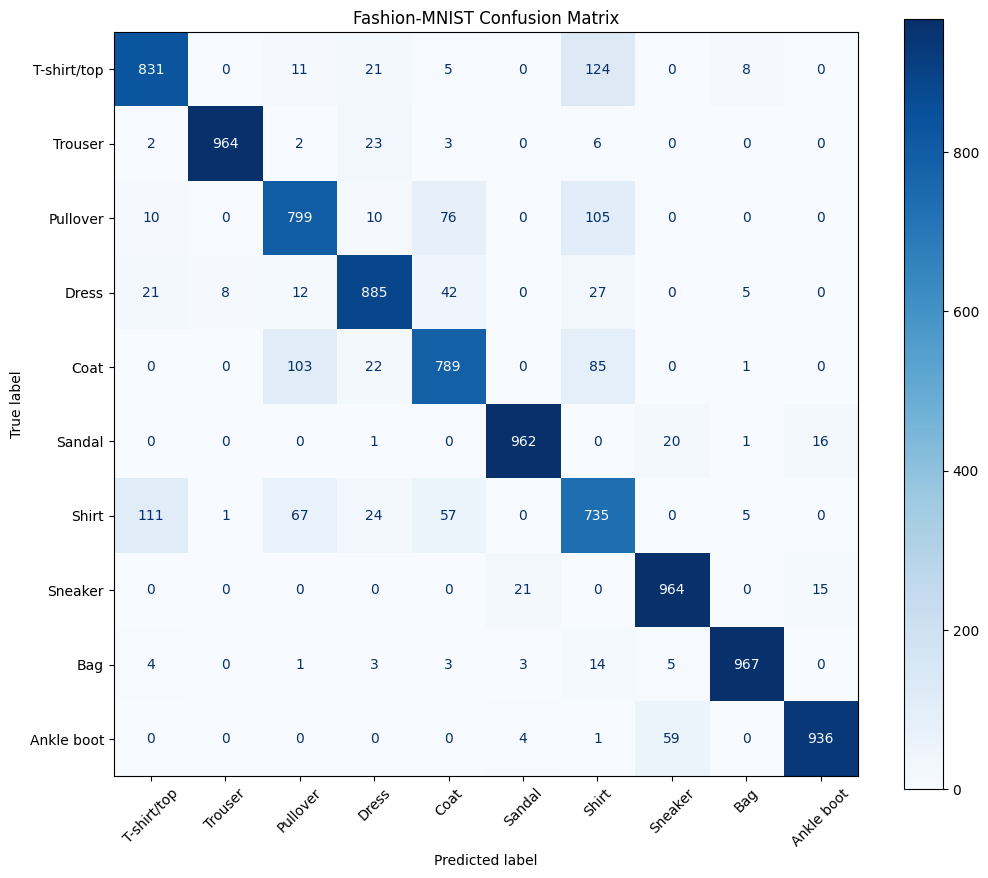

In [ ]:
#check wich part of the model is making mistakes by using a confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

all_predictions = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))
disp.plot(cmap="Blues", xticks_rotation=45, ax=ax)
plt.title("Fashion-MNIST Confusion Matrix")
plt.show()

In [24]:
conv = nn.Conv2d(
    in_channels=1,
    out_channels=32,
    kernel_size=3
)

In [25]:
images, labels = next(iter(train_loader))

feature_maps = conv(images)

print("Original shape:", images.shape)
print("After convolution:", feature_maps.shape)

Original shape: torch.Size([64, 1, 28, 28])
After convolution: torch.Size([64, 32, 26, 26])


In [26]:
relu = nn.ReLU()

activated = relu(feature_maps)

print("After ReLU:", activated.shape)

After ReLU: torch.Size([64, 32, 26, 26])


Max Pooling


In [27]:
pool = nn.MaxPool2d(kernel_size=2)

pooled = pool(activated)

print("Before pooling:", activated.shape)
print("After pooling:", pooled.shape)

Before pooling: torch.Size([64, 32, 26, 26])
After pooling: torch.Size([64, 32, 13, 13])


In [28]:
conv2 = nn.Conv2d(
    in_channels=32,
    out_channels=64,
    kernel_size=3
)

In [29]:
feature_maps2 = conv2(pooled)

print("Before second convolution:", pooled.shape)
print("After second convolution:", feature_maps2.shape)

Before second convolution: torch.Size([64, 32, 13, 13])
After second convolution: torch.Size([64, 64, 11, 11])


In [30]:
activated2 = relu(feature_maps2)

pooled2 = pool(activated2)

print("Before second pooling:", activated2.shape)
print("After second pooling:", pooled2.shape)

Before second pooling: torch.Size([64, 64, 11, 11])
After second pooling: torch.Size([64, 64, 5, 5])


In [31]:
class FashionCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(1600, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

In [32]:
cnn_model = FashionCNN()

print(cnn_model)

FashionCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=1600, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [33]:
images, labels = next(iter(train_loader))

outputs = cnn_model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 1, 28, 28])
Output shape: torch.Size([64, 10])


In [34]:
cnn_loss_fn = nn.CrossEntropyLoss()

cnn_optimizer = torch.optim.Adam(
    cnn_model.parameters(),
    lr=0.001
)

In [ ]:
#train the cnn model
EPOCHS = 10

cnn_history = []

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        cnn_model,
        train_loader,
        cnn_loss_fn,
        cnn_optimizer
    )

    val_loss, val_accuracy = evaluate(
        cnn_model,
        val_loader,
        cnn_loss_fn
    )

    cnn_history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy
    })

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Val Accuracy: {val_accuracy:.4f}"
    )

Epoch [1/10] | Train Loss: 0.5340 | Val Loss: 0.3805 | Val Accuracy: 0.8663
Epoch [2/10] | Train Loss: 0.3470 | Val Loss: 0.3447 | Val Accuracy: 0.8768
Epoch [3/10] | Train Loss: 0.2937 | Val Loss: 0.3027 | Val Accuracy: 0.8900
Epoch [4/10] | Train Loss: 0.2615 | Val Loss: 0.2978 | Val Accuracy: 0.8853
Epoch [5/10] | Train Loss: 0.2343 | Val Loss: 0.2664 | Val Accuracy: 0.9045
Epoch [6/10] | Train Loss: 0.2148 | Val Loss: 0.2969 | Val Accuracy: 0.8902
Epoch [7/10] | Train Loss: 0.1944 | Val Loss: 0.2773 | Val Accuracy: 0.8992
Epoch [8/10] | Train Loss: 0.1770 | Val Loss: 0.2398 | Val Accuracy: 0.9137
Epoch [9/10] | Train Loss: 0.1612 | Val Loss: 0.2383 | Val Accuracy: 0.9117
Epoch [10/10] | Train Loss: 0.1458 | Val Loss: 0.2427 | Val Accuracy: 0.9143


In [36]:
cnn_test_loss, cnn_test_accuracy = evaluate(
    cnn_model,
    test_loader,
    cnn_loss_fn
)

print("CNN Test Loss:", cnn_test_loss)
print("CNN Test Accuracy:", cnn_test_accuracy)

CNN Test Loss: 0.2702520411390408
CNN Test Accuracy: 0.9076


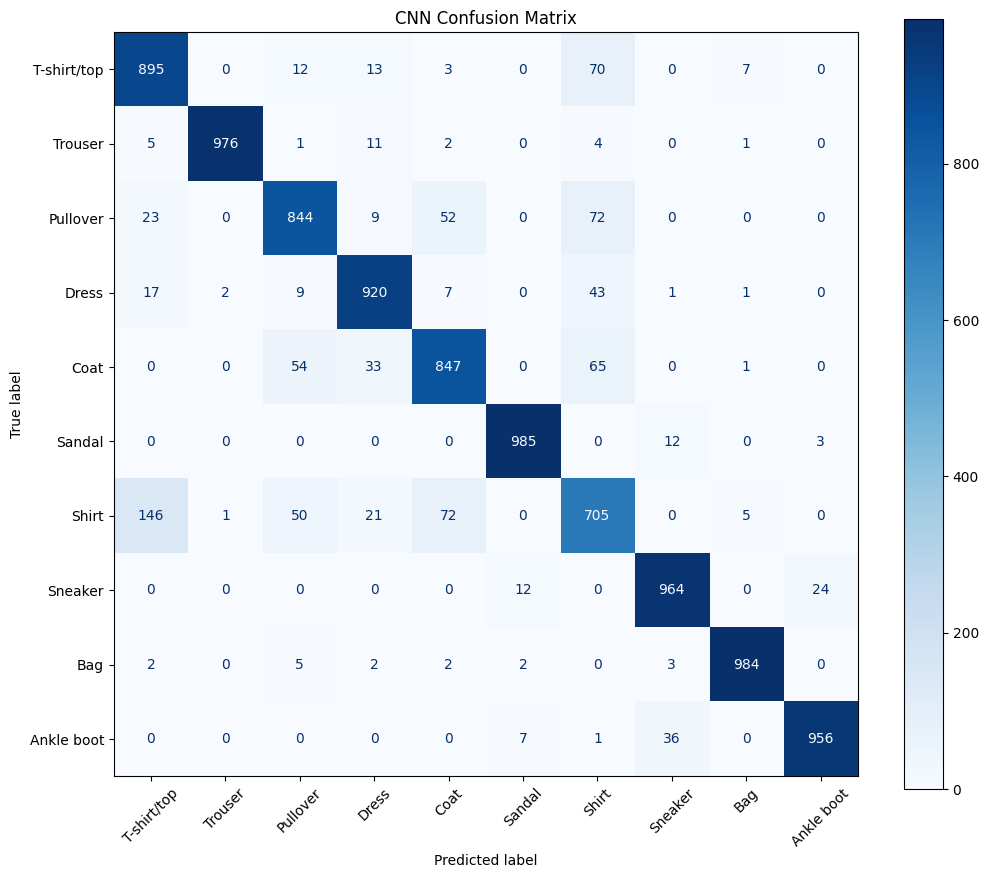

In [37]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

all_predictions = []
all_labels = []

cnn_model.eval()

with torch.no_grad():
    for images, labels in test_loader:

        outputs = cnn_model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.numpy())
        all_labels.extend(labels.numpy())

cnn_cm = confusion_matrix(all_labels, all_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cnn_cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(12, 10))

disp.plot(
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)

plt.title("CNN Confusion Matrix")
plt.show()

In [38]:
torch.save(
    cnn_model.state_dict(),
    "fashion_cnn.pth"
)